# 05 · Part 3: Did Florida's Condo Safety Law Lower Condo Prices?

After the **Champlain Towers South** collapse in Surfside (June 2021, 98 deaths), Florida passed **SB 4-D**,
signed **May 26, 2022**. It applies only to condo buildings **three or more stories tall**:

| Requirement | Who | Deadline |
|---|---|---|
| **Milestone structural inspection** | 3+ story buildings at 30 years old (25 within 3 miles of the coast) | buildings with a certificate of occupancy on or before **July 1, 1992**: first inspection by **Dec 31, 2024** |
| **Structural integrity reserve study (SIRS)** and fully funded reserves for structural components | all 3+ story buildings | reserves no longer waivable for budgets after **Dec 31, 2024** (HB 913, signed June 2025, later extended the SIRS deadline to Dec 31, 2025) |

SB 154 (June 2023) amended the inspection rules. For owners in affected buildings, the law often meant
**special assessments** of tens of thousands of dollars and higher monthly dues, which buyers should
capitalize into lower prices.

**The natural experiment:** buildings under 3 stories are exempt. So compare 3+ story condos (treated) with
1–2 story condos (control), before vs. after, with the sharpest test on **older** tall buildings that faced both
requirements and the Dec 2024 deadline.

*Sources for the legal timeline:*
[Florida Politics on the signing](https://floridapolitics.com/archives/528250-nearly-a-year-after-surfside-condo-collapse-gov-desantis-signs-inspections-bill),
[National Law Review summary](https://natlawreview.com/article/governor-desantis-signs-senate-bill-establishing-building-safety-act-condominium-and),
[Withum on HB 913](https://www.withum.com/resources/key-changes-from-florida-house-bill-913-explained-inspections-reserves-and-more/),
[Fox 35 on the deadline extension](https://www.fox35orlando.com/news/desantis-signs-law-extending-condo-safety-inspection-deadline).

Code: `src/condo.py`.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import condo as C
from plotting import *

warnings.filterwarnings("ignore")
use_style()
pd.set_option("display.width", 200)
FIG = ROOT / "figures"
c = C.load()

## 1. The three groups

The data has no building ID, so buildings are approximated from the parcel ID prefix (the condo complex) plus
year built and story count. That gives **~10,000 buildings**. Height comes from the county GIS layer; "built ≤1992"
matches the statute's July 1, 1992 cutoff.

In [2]:
grp = c.groupby("group").agg(
    sales=("sale_id", "size"), buildings=("building", "nunique"),
    median_ppsf=("price_per_sqft", "median"), median_stories=("stories", "median"),
    in_flood_zone=("sfha", "mean"), gulf_or_bay=("waterfront", lambda w: w.isin(["GULF", "BAY"]).mean()))
grp.style.format({"sales": "{:,}", "buildings": "{:,}", "median_ppsf": "${:,.0f}", "median_stories": "{:.0f}",
                  "in_flood_zone": "{:.0%}", "gulf_or_bay": "{:.0%}"})

,sales,buildings,median_ppsf,median_stories,in_flood_zone,gulf_or_bay
group,,,,,,
1–2 stories (exempt),"26,067","8,612",$180,2,43%,2%
"3+ stories, built after 1992","9,108",888,$234,4,63%,11%
"3+ stories, built ≤1992","5,130",711,$225,4,69%,33%


The treated groups differ from the control group in an important way: **older tall condos are coastal**
(about a third on the Gulf or bay, ~70% in the flood zone). That's exactly where Ian's surge hit, four months
after the law. So every model here includes **Ian controls**: separate post-Ian price shifts for flood-zone units
and for each waterfront type. It also uses **building fixed effects**, so each building is compared only with
its own earlier sales.

## 2. The raw picture

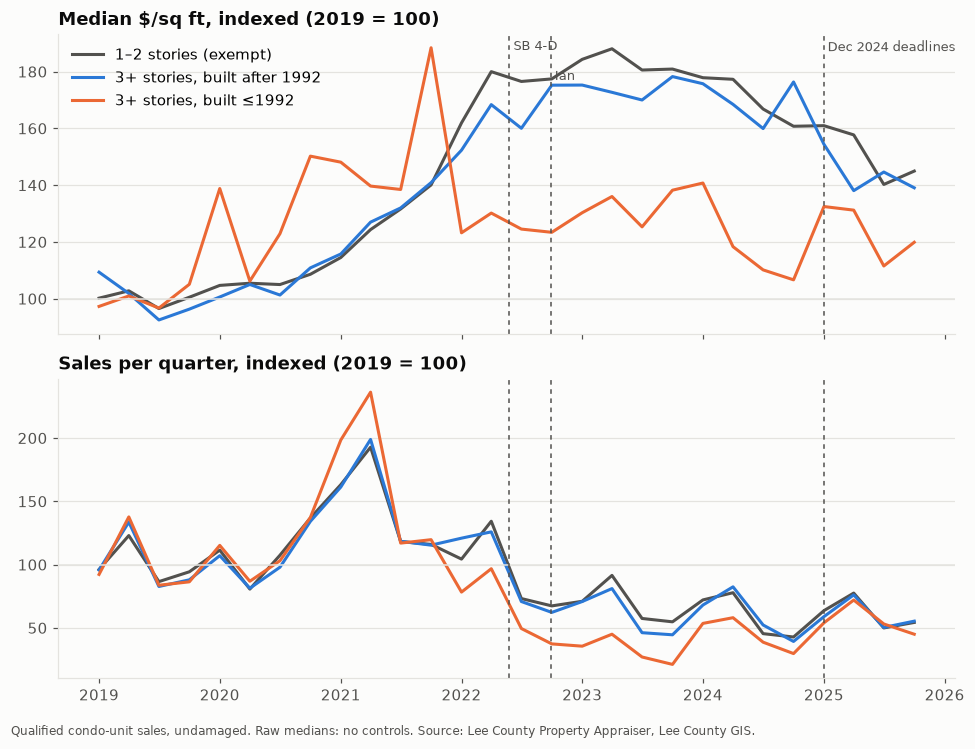

In [3]:
q = (c.groupby([pd.Grouper(key="sale_date", freq="QS"), "group"])
       .agg(ppsf=("price_per_sqft", "median"), sales=("sale_id", "size")).reset_index())
base = q[q["sale_date"].dt.year == 2019].groupby("group")[["ppsf", "sales"]].mean()
q = q.join(base, on="group", rsuffix="_2019")
q["ppsf_idx"], q["sales_idx"] = 100 * q["ppsf"] / q["ppsf_2019"], 100 * q["sales"] / q["sales_2019"]

COL = {"1–2 stories (exempt)": INK2, "3+ stories, built after 1992": C1, "3+ stories, built ≤1992": C2}
fig, axes = plt.subplots(2, 1, figsize=(9, 6.6), sharex=True)
for g, col in COL.items():
    s = q[q["group"] == g]
    axes[0].plot(s["sale_date"], s["ppsf_idx"], color=col, label=g)
    axes[1].plot(s["sale_date"], s["sales_idx"], color=col, label=g)
axes[0].set_title("Median $/sq ft, indexed (2019 = 100)")
axes[1].set_title("Sales per quarter, indexed (2019 = 100)")
axes[0].legend(loc="upper left")
for ax in axes:
    ax.axhline(100, color=GRID, lw=1)
    event(ax, "2022-05-26", "SB 4-D" if ax is axes[0] else "", y=0.98)
    event(ax, "2022-09-28", "Ian" if ax is axes[0] else "", y=0.88)
    event(ax, "2024-12-31", "Dec 2024 deadlines" if ax is axes[0] else "", y=0.98)
year_axis(axes[1])
source_note(fig, "Qualified condo-unit sales, undamaged. Raw medians: no controls. Source: Lee County Property Appraiser, Lee County GIS.")
save(fig, FIG / "05_condo_raw.png")

- **Prices:** the 1–2 story and newer tall groups move almost together. Older tall condos are noisy (few sales per
  quarter), but their median dropped below the others in **early 2022, before the law was signed**: a first hint
  of the pre-trend problem in section 4.
- **Volume:** sales collapsed for every group from mid-2022, to roughly half their 2019 level. For older tall
  buildings they fell furthest and earliest, right around the law and Ian.

Raw medians mix in which units happen to sell, so the next sections use the controlled models.

## 3. Difference-in-differences by phase

Three phases fixed in advance from the statute timeline: **law → end of 2023**, **2024** (the deadline year),
and **2025** (after the Dec 2024 deadlines). Each estimate is the price change for a treated group relative to
exempt 1–2 story condos, versus before the law.

The main model is a **triple difference**: older tall buildings are compared with **older short** buildings,
because anything that penalized older construction in general (e.g., insurers after Ian) would otherwise look like
a law effect.

In [4]:
main = C.phase_estimates(c)
naive = C.phase_estimates(c, age_trends=False)
tab = pd.concat({"triple difference (main)": main[["premium_pct", "lo_pct", "hi_pct"]],
                 "simple DiD (vs all short)": naive[["premium_pct", "lo_pct", "hi_pct"]]}, axis=1)
tab.round(1)

triple difference (main)               simple DiD (vs all short)              
                                            premium_pct lo_pct hi_pct               premium_pct lo_pct hi_pct
group    phase                                                                                               
old_tall law → 2023                                -1.7   -4.5    1.2                      -0.9   -3.3    1.7
new_tall law → 2023                                 0.2   -1.5    1.9                      -0.5   -2.2    1.3
old_tall 2024 (deadline year)                      -6.1  -10.4   -1.6                      -6.7  -10.9   -2.3
new_tall 2024 (deadline year)                      -0.6   -3.2    2.1                      -0.0   -2.6    2.6
old_tall 2025 (after deadline)                     -5.0   -9.3   -0.5                      -8.2  -12.3   -4.0
new_tall 2025 (after deadline)                     -3.7   -6.2   -1.2                      -0.6   -3.2    2.0

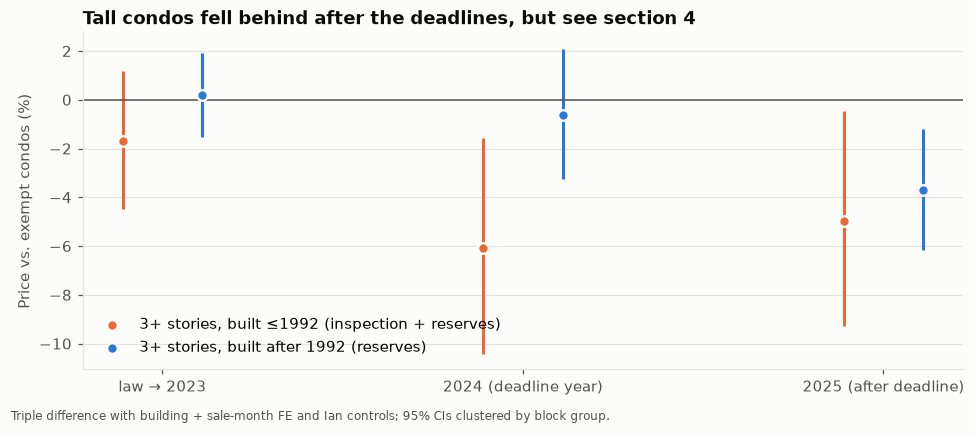

In [5]:
phases = list(C.PHASES)
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (g, label, col) in enumerate([("old_tall", "3+ stories, built ≤1992 (inspection + reserves)", C2),
                                     ("new_tall", "3+ stories, built after 1992 (reserves)", C1)]):
    r = main.loc[g].reindex(phases)
    x = np.arange(len(phases)) + (i - 0.5) * 0.22
    ax.vlines(x, r["lo_pct"], r["hi_pct"], color=col, lw=2)
    ax.scatter(x, r["premium_pct"], color=col, s=48, zorder=3, edgecolor=SURFACE, lw=1.5, label=label)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(len(phases)), phases); ax.grid(axis="x", visible=False)
ax.set_ylabel("Price vs. exempt condos (%)")
ax.set_title("Tall condos fell behind after the deadlines, but see section 4")
ax.legend(loc="lower left")
source_note(fig, "Triple difference with building + sale-month FE and Ian controls; 95% CIs clustered by block group.")
save(fig, FIG / "05_condo_phases.png")

Taken at face value this looks like a law effect: older tall buildings fell **~6% behind** in the deadline
year, and in 2025, when reserve funding became mandatory for *every* 3+ story building, newer tall
buildings fell behind too. That timing matches the statute closely.

But a DiD is only as good as its parallel-trends assumption, and here it's shaky.

## 4. The catch: tall condos were already falling behind

Event study: six-month periods relative to Oct 2021 – Mar 2022, the last full half-year before the law.
Dashed lines extend each group's **pre-law trend**.

3+ stories, built ≤1992: pre-law trend -0.50 points per half-year
3+ stories, built after 1992: pre-law trend -0.67 points per half-year


estimate  pre-law trend  deviation from trend
group                        period start                                               
3+ stories, built ≤1992      Apr 2022           0.4           -0.0                   0.4
                             Oct 2022          -0.5           -0.5                   0.0
                             Apr 2023           1.9           -1.0                   2.9
                             Oct 2023          -0.3           -1.5                   1.2
                             Apr 2024          -4.7           -2.0                  -2.7
                             Oct 2024          -4.1           -2.5                  -1.6
                             Apr 2025          -3.1           -3.0                  -0.0
                             Oct 2025          -5.6           -3.5                  -2.0
3+ stories, built after 1992 Apr 2022           0.1            0.3                  -0.2
                             Oct 2022           4.2           -0.3                   4.5
                             Apr 2023           2.5           -1.0                   3.5
                             Oct 2023           2.6           -1.7                   4.3
                             Apr 2024           1.7           -2.3                   4.1
                             Oct 2024           0.2           -3.0                   3.2
                             Apr 2025          -0.6           -3.7                   3.1
                             Oct 2025          -2.8           -4.3                   1.5

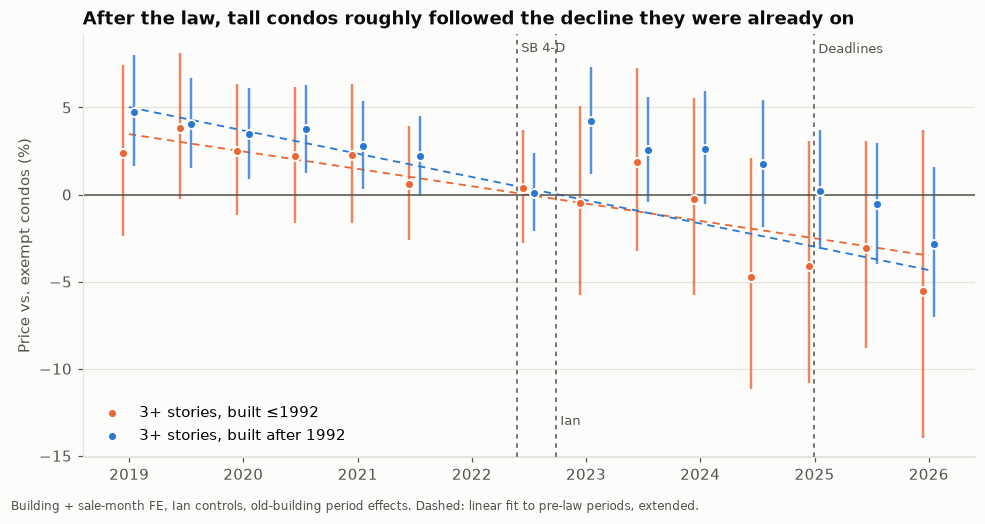

In [6]:
es = C.event_study(c)
fig, ax = plt.subplots(figsize=(9, 4.6))
dev_rows = []
for i, (g, label, col) in enumerate([("old_tall", "3+ stories, built ≤1992", C2), ("new_tall", "3+ stories, built after 1992", C1)]):
    e = es[es["group"] == g].copy()
    pre = pd.concat([e.loc[e["period"] < -2, ["period", "premium_pct"]], pd.DataFrame({"period": [-2], "premium_pct": [0.0]})])
    slope, icpt = np.polyfit(pre["period"], pre["premium_pct"], 1)
    e["trend"] = slope * e["period"] + icpt
    x = e["start"] + pd.Timedelta(days=91 + (i - 0.5) * 36)
    ax.vlines(x, e["lo_pct"], e["hi_pct"], color=col, lw=1.6, alpha=0.8)
    ax.scatter(x, e["premium_pct"], color=col, s=34, zorder=3, edgecolor=SURFACE, lw=1.2, label=label)
    span = np.arange(e["period"].min(), e["period"].max() + 1)
    ax.plot([C.IAN + pd.DateOffset(months=6 * p) + pd.Timedelta(days=91) for p in span], slope * span + icpt,
            color=col, lw=1.2, ls=(0, (4, 3)))
    post = e[e["period"] >= -1]
    dev_rows.append(pd.DataFrame({"group": label, "period start": post["start"].dt.strftime("%b %Y"),
                                  "estimate": post["premium_pct"], "pre-law trend": post["trend"],
                                  "deviation from trend": post["premium_pct"] - post["trend"]}))
    print(f"{label}: pre-law trend {slope:+.2f} points per half-year")
ax.axhline(0, color=INK2, lw=1)
event(ax, "2022-05-26", "SB 4-D", y=0.98); event(ax, "2022-09-28", "Ian", y=0.10); event(ax, "2024-12-31", "Deadlines", y=0.98)
ax.set_ylabel("Price vs. exempt condos (%)")
ax.set_title("After the law, tall condos roughly followed the decline they were already on")
ax.legend(loc="lower left"); year_axis(ax)
source_note(fig, "Building + sale-month FE, Ian controls, old-building period effects. Dashed: linear fit to pre-law periods, extended.")
save(fig, FIG / "05_condo_event_study.png")
pd.concat(dev_rows).round(1).set_index(["group", "period start"])

**Read:**
- From 2019 to early 2022, *before* SB 4-D, both tall groups were already losing ground to low-rise condos:
  about half a point per half-year.
- After the law, older tall condos drop a few points **below** that trend in 2024 (the deadline year),
  but the deviations are only 0–3 points, and every confidence interval spans zero.
- Newer tall condos sit **above** their pre-law trend throughout.

Re-estimating the phase model with group-specific linear trends gives the same answer:

In [7]:
rob = {}
rob["Main: triple difference"] = main
rob["+ group-specific linear trends"] = C.phase_estimates(c, linear_trends=True)
rob["No Ian controls"] = C.phase_estimates(c, ian=False)
rob["Include storm-damaged sales"] = C.phase_estimates(C.load(damaged=True))
near = c[c["stories"].between(2, 4)]
rob["Near the cutoff: 2 vs. 3–4 stories"] = C.phase_estimates(near)
rob["Block group × post-Ian FE instead of building FE"] = C.phase_estimates(c, fe=lambda x: x["block_group"] + "_" + x["post_ian"].astype(str))
rt = pd.concat({k: v["premium_pct"].round(1).astype(str) + "  [" + v["lo_pct"].round(1).astype(str) + ", " + v["hi_pct"].round(1).astype(str) + "]"
                for k, v in rob.items()}, axis=1).T
rt.columns = [f"{'old' if g == 'old_tall' else 'new'} tall | {p}" for g, p in rt.columns]
rt[[f"old tall | {p}" for p in C.PHASES] + [f"new tall | {p}" for p in C.PHASES]]

,old tall | law → 2023,old tall | 2024 (deadline year),old tall | 2025 (after deadline),new tall | law → 2023,new tall | 2024 (deadline year),new tall | 2025 (after deadline)
Main: triple difference,"-1.7 [-4.5, 1.2]","-6.1 [-10.4, -1.6]","-5.0 [-9.3, -0.5]","0.2 [-1.5, 1.9]","-0.6 [-3.2, 2.1]","-3.7 [-6.2, -1.2]"
+ group-specific linear trends,"0.4 [-3.4, 4.3]","-2.9 [-9.7, 4.3]","-0.9 [-8.4, 7.3]","3.4 [0.9, 5.9]","4.5 [0.6, 8.5]","2.7 [-1.6, 7.0]"
No Ian controls,"-1.5 [-4.4, 1.5]","-6.2 [-10.0, -2.1]","-5.9 [-10.2, -1.5]","-1.8 [-3.7, 0.0]","-3.3 [-6.2, -0.3]","-6.5 [-9.0, -4.0]"
Include storm-damaged sales,"-3.5 [-6.4, -0.6]","-5.6 [-9.8, -1.2]","-2.7 [-8.1, 2.9]","0.3 [-1.5, 2.1]","0.0 [-2.6, 2.7]","-3.0 [-5.6, -0.4]"
Near the cutoff: 2 vs. 3–4 stories,"-0.7 [-3.9, 2.7]","-4.5 [-9.4, 0.8]","-0.4 [-6.6, 6.3]","0.2 [-1.7, 2.2]","-0.4 [-3.3, 2.7]","-4.4 [-7.4, -1.4]"
Block group × post-Ian FE instead of building FE,"-2.3 [-6.1, 1.6]","-8.8 [-14.5, -2.8]","-5.0 [-10.7, 1.1]","3.2 [-0.2, 6.7]","1.7 [-2.1, 5.7]","-0.9 [-5.9, 4.3]"


Most specifications show older tall condos **~4–9% behind** in the 2024 deadline year. But once each group's pre-existing
trend is allowed for, the effect shrinks to a few points and is no longer distinguishable from zero.
The narrow comparison of 2-story vs. 3–4-story buildings, the cleanest test of the 3-story cutoff, is also
inconclusive.

## 5. Conclusions

1. **Tall condos did fall behind low-rise condos after 2022**: ~6% for older tall buildings in the 2024
   deadline year, and newer tall buildings joining in 2025 when reserve funding became mandatory for all 3+
   story buildings. The timing lines up with the statute.
2. **But the decline started before the law.** Tall condos had been losing ground since 2019, and relative
   to that trend the post-law deviation is small (≈0–3 points) and statistically indistinguishable from zero.
3. **Verdict: not proven.** Sales prices alone can't separate a modest SB 4-D effect from a longer-running
   shift away from high-rise condos. That shift has plausible causes of its own: insurance costs for coastal
   high-rises, a buyer preference for low-rise living, and Southwest Florida's supply of new low-rise product.

**Why this negative result is still worth reporting:** the naive design gives a clean-looking, statute-timed
6–8% discount, the kind of number that ends up in headlines. Testing parallel trends shows it can't carry
that weight.

**What would settle it:** association-level data on **special assessments, HOA dues, and SIRS filings**
(Florida's DBPR collects milestone and SIRS reports), plus listing data (days on market, price cuts) to see
whether the law hit **liquidity** before price. The volume collapse in section 2 hints that it may have.